# Setup

Roll number, name and the starter dataset generator. `generate_dataset()` and `process_ticket()` are used exactly as provided.

In [1]:
ROLL_NO = 1024170231
NAME = "Tarush"

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170231   Name: Tarush   Fingerprint: 4F010D88   Tickets: 13

Ticket_ID                                                                           Ticket_Text
      T01                                                           The file is 95.5% uploaded.
      T02      Server keeps asking for login before the assignment deadline. Please resolve it.
      T03                                                       Is it fixed?? Pls reply ASAP :(
      T04                                          Call me on +91 98765 43210 or 0175-239-3201.
      T05 I tried restarting the Python after resetting my password. I don't know what changed.
      T06                          E-mail is showing an error on my laptop. Can you check this?
      T07                   Laptop keeps disconnecting after the latest update. This is urgent.
      T08                                The printer failed to open. Is there another solution?
      T09                I cannot access the VPN while upl

# Question 1

Run `process_ticket()` on every ticket and tabulate the counts.

In [5]:
results = [process_ticket(text) for text in df["Ticket_Text"]]

summary = pd.DataFrame({
    "Ticket_ID": df["Ticket_ID"],
    "Sentences": [len(r["sentences"]) for r in results],
    "Tokens": [len(r["tokens"]) for r in results],
    "Punctuation": [len(r["punct"]) for r in results],
    "Stopwords": [len(r["stops"]) for r in results],
    "Unique_Tokens": [len(set(r["tokens"])) for r in results],
    "Final_Tokens": [len(r["final"]) for r in results],
})

total_row = summary.drop(columns="Ticket_ID").sum().to_frame().T
total_row.insert(0, "Ticket_ID", "TOTAL")
summary = pd.concat([summary, total_row], ignore_index=True)
print(summary.to_string(index=False))

Ticket_ID  Sentences  Tokens  Punctuation  Stopwords  Unique_Tokens  Final_Tokens
      T01          1       7            2          2              7             3
      T02          2      14            2          4             13             8
      T03          2      10            4          2              9             4
      T04          1       9            1          3              9             5
      T05          2      17            2          7             15             8
      T06          2      14            2          7             14             5
      T07          2      12            2          4             11             6
      T08          2      11            2          4             11             5
      T09          2      15            2          7             13             6
      T10          2      12            2          4             11             6
      T11          1      11            2          3             10             6
      T12       

The unique-token total is the sum of per-ticket unique counts, not the corpus-wide vocabulary size (that is computed in Question 5).

### Tokens of the selected ticket

In [6]:
focus_id = FOCUS[0]
focus_text = df.loc[df["Ticket_ID"] == focus_id, "Ticket_Text"].iloc[0]
focus = results[df.index[df["Ticket_ID"] == focus_id][0]]

print("Ticket :", focus_id, "-", focus_text)
print("Tokens     :", focus["tokens"])
print("Punctuation:", focus["punct"])
print("Stopwords  :", focus["stops"])
print("Final      :", focus["final"])

Ticket : T02 - Server keeps asking for login before the assignment deadline. Please resolve it.
Tokens     : ['server', 'keeps', 'asking', 'for', 'login', 'before', 'the', 'assignment', 'deadline', '.', 'please', 'resolve', 'it', '.']
Punctuation: ['.', '.']
Stopwords  : ['for', 'before', 'the', 'it']
Final      : ['server', 'keeps', 'asking', 'login', 'assignment', 'deadline', 'please', 'resolve']


**Observe:** The final tokens that are not real words are:

- `n't` (4 times) and `wo`. `word_tokenize()` splits a contraction such as `won't` into `wo` + `n't`, and `don't`, `couldn't` and `isn't` into a stem plus `n't`. The stopword list contains `not` and `don` but not `n't` or `wo`, so these fragments survive the stopword filter.
- Number and phone fragments such as `+91`, `98765`, `43210`, `0175-239-3201` and `95.5`. They are not stopwords or punctuation, so they stay in the final tokens.
- Informal forms such as `pls`, `asap` and `vpn`, which are abbreviations rather than dictionary words.

# Question 2

Regex extraction and replacement on the raw tickets.

In [7]:
import re

LONG_WORDS = r"\b[A-Za-z]{6,}(?:'[a-z]+)?\b"
NUMBERS = r"0x[0-9A-Fa-f]+|\d+(?:,\d{3})*(?:\.\d+)*"
CAPITALIZED = r"\b[A-Z][a-z]+(?:-[A-Z][a-z]+)*\b"
VOWEL_WORDS = r"(?<![\w'./@-])[aeiouAEIOU][A-Za-z]*(?:['-][A-Za-z]+)*\b(?![.@-]\w)"

EMAIL = r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+"
URL = r"(?:https?://|www\.)[\w\-./?=&%#~:+]*[\w/]"
PHONE = r"\+\d{1,3}[\s-]?\d{5}[\s-]?\d{5}|0\d{3,4}-\d{3}-\d{4}"

Capitalized words are title-case words (`Server`, `Wi-Fi`). All-caps acronyms such as `VPN` or `MATLAB` are not counted.

In [8]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

### `re.findall()` extraction

In [9]:
def extract(text):
    return {
        "Long words (>5 letters)": re.findall(LONG_WORDS, text),
        "Numbers": re.findall(NUMBERS, text),
        "Capitalized words": re.findall(CAPITALIZED, text),
        "Vowel-initial words": re.findall(VOWEL_WORDS, text),
    }


def show_extraction(title, text):
    print(f"--- {title}")
    for name, found in extract(text).items():
        print(f"{name:25}: {found}")
    print()


show_extraction("TEST_LINES", "\n".join(TEST_LINES))
show_extraction("Tickets", "\n".join(df["Ticket_Text"]))

--- TEST_LINES
Long words (>5 letters)  : ['helpdesk', 'thapar', 'thapar', 'thapar', 'Version']
Numbers                  : ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1,250', '5.30']
Capitalized words        : ['Mail', 'Call', 'Version', 'Rs', 'The']
Vowel-initial words      : ['or', 'or', 'or', 'is', "isn't", 'open', 'at']

--- Tickets
Long words (>5 letters)  : ['uploaded', 'Server', 'asking', 'before', 'assignment', 'deadline', 'Please', 'resolve', 'restarting', 'Python', 'resetting', 'password', 'changed', 'showing', 'laptop', 'Laptop', 'disconnecting', 'latest', 'update', 'urgent', 'printer', 'failed', 'another', 'solution', 'cannot', 'access', 'uploading', 'worked', 'yesterday', 'printer', 'crashes', 'opening', 'another', 'computer', 'printer', 'jammed', 'MATLAB', 'working', "couldn't", 'connect', 'Python', 'before', 'assignment', 'deadline', 'worked', 'yesterday']
Numbers                  : ['95.5', '91', '98765', '43210', '0175', '2

### `re.sub()` replacement

In [10]:
def mask(text):
    text = re.sub(EMAIL, "<EMAIL>", text)
    text = re.sub(URL, "<URL>", text)
    return re.sub(PHONE, "<PHONE>", text)


for line in TEST_LINES:
    print("Before:", line)
    print("After :", mask(line), "\n")

for ticket_id, text in zip(df["Ticket_ID"], df["Ticket_Text"]):
    masked = mask(text)
    if masked != text:
        print(ticket_id, "|", text)
        print(" " * len(ticket_id), "|", masked, "\n")

Before: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
After : Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>. 

Before: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
After : Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250. 

Before: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
After : The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work. 

T04 | Call me on +91 98765 43210 or 0175-239-3201.
    | Call me on <PHONE> or <PHONE>. 



In [11]:
from nltk.tokenize import sent_tokenize

all_capitalized = 0
sentence_start_only = 0

for text in df["Ticket_Text"]:
    all_capitalized += len(re.findall(CAPITALIZED, text))
    sentence_start_only += sum(bool(re.match(CAPITALIZED, s)) for s in sent_tokenize(text))

print("Capitalized words in tickets   :", all_capitalized)
print("Capitalized only at sentence start:", sentence_start_only)

Capitalized words in tickets   : 20
Capitalized only at sentence start: 18


**Observe:** 18 of the 20 capitalized words are capitalized only because they start a sentence (`The`, `Server`, `Please`, `Is`, `Call`, `Can`, ...). Only the two occurrences of `Python` are capitalized because they are a proper noun.

# Question 3

Custom tokenizer with a single `RegexpTokenizer` pattern.

In [12]:
from nltk.tokenize import RegexpTokenizer

TOKEN_PATTERN = "|".join([
    r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+",                      # email
    r"(?:https?://|www\.)[\w\-./?=&%#~:+]*[\w/]",          # URL
    r"\+\d{1,3}[\s-]?\d{5}[\s-]?\d{5}|0\d{3,4}-\d{3}-\d{4}",  # phone number
    r"0x[0-9A-Fa-f]+",                                     # hex code
    r"\d+(?:-\d+)+",                                       # dashed id
    r"\d+(?:,\d{3})*(?:\.\d+)*",                           # integer, decimal, version
    r"(?:[A-Za-z]\.){2,}",                                  # abbreviation such as p.m.
    r"[A-Za-z]+(?:['\u2019-][A-Za-z0-9]+)*",                # word, contraction, hyphenated
    r"\.{3}|[^\w\s]",                                      # ellipsis or any other symbol
])

tokenizer = RegexpTokenizer(TOKEN_PATTERN)


def my_tokenize(text):
    return tokenizer.tokenize(text)

### On `TEST_LINES`

In [13]:
for line in TEST_LINES:
    print(line)
    print(my_tokenize(line), "\n")

Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.'] 

Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.'] 

The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
['The', 'state-of-the-art', 'lab', "isn't", 'open', ';', 'log-in', 'at', '5.30', 'p.m.', "didn't", 'work', '.'] 



### On the tickets

In [14]:
for ticket_id, text in zip(df["Ticket_ID"], df["Ticket_Text"]):
    print(ticket_id, my_tokenize(text))

T01 ['The', 'file', 'is', '95.5', '%', 'uploaded', '.']
T02 ['Server', 'keeps', 'asking', 'for', 'login', 'before', 'the', 'assignment', 'deadline', '.', 'Please', 'resolve', 'it', '.']
T03 ['Is', 'it', 'fixed', '?', '?', 'Pls', 'reply', 'ASAP', ':', '(']
T04 ['Call', 'me', 'on', '+91 98765 43210', 'or', '0175-239-3201', '.']
T05 ['I', 'tried', 'restarting', 'the', 'Python', 'after', 'resetting', 'my', 'password', '.', 'I', "don't", 'know', 'what', 'changed', '.']
T06 ['E-mail', 'is', 'showing', 'an', 'error', 'on', 'my', 'laptop', '.', 'Can', 'you', 'check', 'this', '?']
T07 ['Laptop', 'keeps', 'disconnecting', 'after', 'the', 'latest', 'update', '.', 'This', 'is', 'urgent', '.']
T08 ['The', 'printer', 'failed', 'to', 'open', '.', 'Is', 'there', 'another', 'solution', '?']
T09 ['I', 'cannot', 'access', 'the', 'VPN', 'while', 'uploading', 'the', 'file', '.', 'It', 'worked', 'yesterday', '.']
T10 ['The', 'printer', 'crashes', 'while', 'opening', '.', 'It', 'works', 'on', 'another', 'com

### Comparison with `word_tokenize()`

In [15]:
from collections import Counter

different = []
for ticket_id, text in zip(df["Ticket_ID"], df["Ticket_Text"]):
    mine, nltk_tokens = my_tokenize(text), word_tokenize(text)
    if mine != nltk_tokens:
        different.append(ticket_id)

print(f"Tickets tokenized differently: {len(different)} of {len(df)}")
print(different)

Tickets tokenized differently: 5 of 13
['T04', 'T05', 'T09', 'T11', 'T13']


In [16]:
def compare(text):
    mine, theirs = my_tokenize(text), word_tokenize(text)
    only_mine = list((Counter(mine) - Counter(theirs)).elements())
    only_theirs = list((Counter(theirs) - Counter(mine)).elements())
    return only_mine, only_theirs


print("--- TEST_LINES")
for line in TEST_LINES:
    only_mine, only_theirs = compare(line)
    print("my_tokenize only :", only_mine)
    print("word_tokenize only:", only_theirs, "\n")

print("--- Tickets")
for ticket_id, text in zip(df["Ticket_ID"], df["Ticket_Text"]):
    only_mine, only_theirs = compare(text)
    if only_mine or only_theirs:
        print(ticket_id, "| my_tokenize only:", only_mine, "| word_tokenize only:", only_theirs)

--- TEST_LINES
my_tokenize only : ['it.helpdesk@thapar.edu', 'a.b-c@dept.univ.ac.in', 'https://lms.thapar.edu/help']
word_tokenize only: ['it.helpdesk', '@', '@', 'thapar.edu', 'a.b-c', 'dept.univ.ac.in', 'https', ':', '//lms.thapar.edu/help'] 

my_tokenize only : ['+91 98765 43210']
word_tokenize only: ['+91', '98765', '43210'] 

my_tokenize only : ["isn't", "didn't"]
word_tokenize only: ['is', "n't", "n't", 'did'] 

--- Tickets
T04 | my_tokenize only: ['+91 98765 43210'] | word_tokenize only: ['+91', '98765', '43210']
T05 | my_tokenize only: ["don't"] | word_tokenize only: ['do', "n't"]
T09 | my_tokenize only: ['cannot'] | word_tokenize only: ['can', 'not']
T11 | my_tokenize only: ["won't", "isn't"] | word_tokenize only: ['wo', "n't", "n't", 'is']
T13 | my_tokenize only: ["couldn't"] | word_tokenize only: ['could', "n't"]


**Observe:** 5 of the 13 tickets (T04, T05, T09, T11, T13) are tokenized differently by `my_tokenize` and `word_tokenize`.

Differences between the two tokenizers:

1. **Contractions.** `word_tokenize` splits `isn't` into `is` + `n't`, `won't` into `wo` + `n't` and `couldn't` into `could` + `n't`. `my_tokenize` keeps each contraction as one token.
2. **Phone numbers.** `word_tokenize` gives `+91`, `98765`, `43210` as three tokens. `my_tokenize` keeps `+91 98765 43210` as one token, because the phone alternative comes before the number alternative in the pattern.
3. **Emails and URLs.** `word_tokenize` breaks `https://lms.thapar.edu/help` into `https`, `:` and `//lms.thapar.edu/help`, and splits email addresses at `@`. `my_tokenize` keeps both whole.
4. **`cannot`.** `word_tokenize` splits it into `can` + `not`. `my_tokenize` has no rule for this and keeps it as one word.

Both tokenizers keep `state-of-the-art`, `log-in`, `2.0.1`, `95.5` and `p.m.` whole. `word_tokenize` also splits `95.5%` into `95.5` and `%`, the same as `my_tokenize`.

# Question 4

Stemming and lemmatization on the unique final tokens.

In [17]:
from nltk import pos_tag
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.corpus import wordnet

unique_final = sorted({w for r in results for w in r["final"]})
print(len(unique_final), "unique final tokens")
print(unique_final)

58 unique final tokens
['+91', '0175-239-3201', '43210', '95.5', '98765', 'access', 'another', 'asap', 'asking', 'assignment', 'call', 'changed', 'check', 'computer', 'connect', 'could', 'crashes', 'deadline', 'disconnecting', 'e-mail', 'error', 'failed', 'file', 'fixed', 'jammed', 'keeps', 'know', 'laptop', 'latest', 'login', 'matlab', "n't", 'open', 'opening', 'password', 'please', 'pls', 'print', 'printer', 'python', 'reply', 'resetting', 'resolve', 'restarting', 'server', 'showing', 'solution', 'tried', 'update', 'uploaded', 'uploading', 'urgent', 'vpn', 'wo', 'worked', 'working', 'works', 'yesterday']


Many of the unique final tokens end in **-ing**: `asking`, `disconnecting`, `opening`, `restarting`, `showing`, `uploading`, `working` and `resetting`. Removing `ing` turns them into useful roots (`ask`, `upload`, `work`, `restart`), so the Regexp Stemmer uses the rule `ing$` with a minimum word length of 4. A rule for `-ed` would also have been possible (`worked`, `failed`, `uploaded`), but `-ing` is the most frequent suffix and the rule is safe on short words because of the length limit.

In [18]:
porter = PorterStemmer()
lancaster = LancasterStemmer()
regexp = RegexpStemmer("ing$", min=4)
lemmatizer = WordNetLemmatizer()


def wordnet_pos(tag):
    return {"J": wordnet.ADJ, "V": wordnet.VERB, "R": wordnet.ADV}.get(tag[0], wordnet.NOUN)


# Tag each sentence with its original casing so the tagger sees the context.
word_tags = {}
for r in results:
    for sentence in r["sentences"]:
        for token, tag in pos_tag(word_tokenize(sentence)):
            word_tags.setdefault(token.lower(), tag)

rows = []
for word in unique_final:
    tag = word_tags[word]
    rows.append({
        "Word": word,
        "POS": tag,
        "Porter": porter.stem(word),
        "Lancaster": lancaster.stem(word),
        "Regexp": regexp.stem(word),
        "Lemma": lemmatizer.lemmatize(word, wordnet_pos(tag)),
    })

stem_df = pd.DataFrame(rows)
differs = stem_df[stem_df[["Porter", "Lancaster", "Regexp", "Lemma"]].nunique(axis=1) > 1]
print(f"{len(differs)} of {len(stem_df)} words have differing outputs\n")
print(differs.to_string(index=False))

30 of 58 words have differing outputs

      Word POS  Porter Lancaster     Regexp      Lemma
   another  DT   anoth     anoth    another    another
assignment  JJ  assign    assign assignment assignment
      call  VB    call       cal       call       call
   changed VBD   chang     chang    changed     change
  computer  NN  comput    comput   computer   computer
   crashes NNS   crash     crash    crashes      crash
  deadline  NN deadlin   deadlin   deadline   deadline
     error  NN   error        er      error      error
    failed VBD    fail      fail     failed       fail
      file  NN    file       fil       file       file
     fixed VBN     fix       fix      fixed        fix
    jammed VBN     jam       jam     jammed        jam
     keeps VBZ    keep      keep      keeps       keep
    latest JJS  latest    latest     latest       late
      open  VB    open        op       open       open
   opening  NN    open        op       open    opening
    please NNP   pleas    

**Observe:**

- **Over-stemming:** Lancaster reduces `open` and `opening` to `op`, and `error` to `er`. These stems lose the meaning and could collide with unrelated words. The Regexp rule also over-stems `resetting` to `resett`, because it does not handle the doubled consonant.
- **Under-stemming:** Porter keeps `printer` and `print` apart (the table shows `printer` unchanged under Porter but `print` under Lancaster). The Regexp stemmer leaves `worked`, `failed`, `uploaded` and `crashes` untouched because it only knows `-ing`.
- The lemmatizer gives real words and depends on the tag: `tried` (VBD) becomes `try`, while `opening` was tagged as a noun in this context and stays `opening`.

# Question 5

Corpus statistics.

In [19]:
S1 = [t for r in results for t in r["tokens"]]
S2 = [t for t in S1 if not is_punct(t)]
S3 = [t for r in results for t in r["final"]]
S4 = [porter.stem(t) for t in S3]

stats = pd.DataFrame({
    "Set": ["S1 all tokens", "S2 no punctuation", "S3 final tokens", "S4 S3 + Porter"],
    "Total": [len(s) for s in (S1, S2, S3, S4)],
    "Unique": [len(set(s)) for s in (S1, S2, S3, S4)],
})
stats["TTR"] = (stats["Unique"] / stats["Total"]).round(4)
print(stats.to_string(index=False))

              Set  Total  Unique    TTR
    S1 all tokens    159      85 0.5346
S2 no punctuation    132      79 0.5985
  S3 final tokens     73      58 0.7945
   S4 S3 + Porter     73      54 0.7397


### Top 10 words

In [20]:
print("S1:", Counter(S1).most_common(10))
print("S3:", Counter(S3).most_common(10))

S1: [('.', 18), ('the', 12), ('is', 7), ('it', 6), ('?', 5), ('i', 4), ("n't", 4), ('on', 3), ('can', 3), ('this', 3)]
S3: [("n't", 4), ('printer', 3), ('file', 2), ('keeps', 2), ('assignment', 2), ('deadline', 2), ('python', 2), ('laptop', 2), ('check', 2), ('another', 2)]


### log(rank) vs log(frequency) for S3

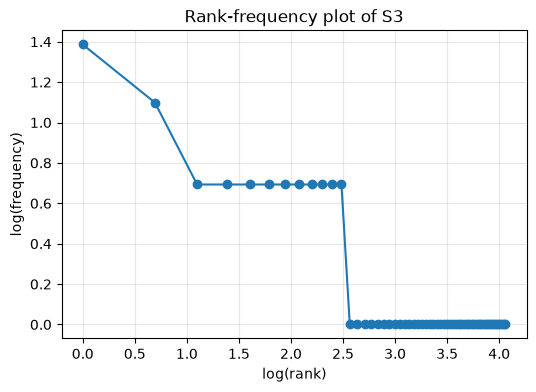

In [21]:
import numpy as np
import matplotlib.pyplot as plt

freqs = sorted(Counter(S3).values(), reverse=True)
ranks = np.arange(1, len(freqs) + 1)

plt.figure(figsize=(6, 4))
plt.plot(np.log(ranks), np.log(freqs), marker="o")
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("Rank-frequency plot of S3")
plt.grid(True, alpha=0.3)
plt.show()

### Top 5 bigrams

In [22]:
from itertools import chain
from nltk import bigrams


def top_bigrams(token_lists, n=5):
    return Counter(chain.from_iterable(bigrams(tokens) for tokens in token_lists)).most_common(n)


print("S1:", top_bigrams([r["tokens"] for r in results]))
print("S3:", top_bigrams([r["final"] for r in results]))

S1: [(('the', 'printer'), 3), (('.', 'it'), 3), (('the', 'file'), 2), (('before', 'the'), 2), (('the', 'assignment'), 2)]
S3: [(('assignment', 'deadline'), 2), (('worked', 'yesterday'), 2), (('file', '95.5'), 1), (('95.5', 'uploaded'), 1), (('server', 'keeps'), 1)]


Bigrams are built within each ticket, so no pair spans two different tickets.

**Observe:** The total stays at 73 from S3 to S4, but the vocabulary shrinks from 58 to 54, so the TTR falls from 0.7945 to 0.7397. TTR rises from S1 (0.5346) to S2 (0.5985) and S3 (0.7945) because the tokens removed are repeated ones: punctuation (`.` appears 18 times) and stopwords (`the` appears 12 times). Removing them cuts the total much more than the unique count.

# Question 6

Interpretation.

**(a)** TTR = unique tokens / total tokens.

- **S1 → S2** (0.5346 → 0.5985): removing the 27 punctuation tokens drops the total from 159 to 132 but only 6 unique types (`.`, `?`, `;`, `:`, `(`, `%`), so the ratio rises.
- **S2 → S3** (0.5985 → 0.7945): stopwords such as `the`, `is`, `it` and `on` are the most repeated tokens. Removing them cuts the total from 132 to 73 while the unique count falls only from 79 to 58.
- **S3 → S4** (0.7945 → 0.7397): the total does not change, but Porter merges different forms of one word (`worked`/`works`/`work`, `uploaded`/`uploading`, `open`/`opening`), so the unique count drops from 58 to 54.

**(b)** For `won't`, `word_tokenize()` gives `wo` + `n't`, while `my_tokenize` gives `won't`. NLTK follows Penn Treebank rules, which split the negation from the verb. That leaves the meaningless fragment `wo` in the output, and `my_tokenize` keeps the original word.

**(c)** Lancaster stems `opening` and `open` to `op`, and `error` to `er`. These stems are not words and lose the meaning. Porter also turns `tried` into `tri` and `reply` into `repli`.

**(d)** `changed` is tagged as a past-tense verb, so the lemmatizer returns `change` while Porter returns `chang`. Similarly `tried` becomes `try` instead of `tri`. Without the POS tag the lemmatizer treats the word as a noun and leaves it as `changed`, as the cell below shows.

In [23]:
for word in ["changed", "tried"]:
    print(f"{word:8} | Porter: {porter.stem(word):6} | lemma (noun, default): {lemmatizer.lemmatize(word):8} | lemma (verb): {lemmatizer.lemmatize(word, wordnet.VERB)}")

changed  | Porter: chang  | lemma (noun, default): changed  | lemma (verb): change
tried    | Porter: tri    | lemma (noun, default): tried    | lemma (verb): try
